# Why the model flags a student: SHAP explanations (ticket 215, SCRUM-187)

**Question.** For any student in the Day 30 population, which inputs move the risk score, and how can that be said in plain language? **Model.** A PROVISIONAL Random Forest retrained by `scripts/train_forest.py` from the tuned settings of ticket 212; it is a stand-in until ticket 214 delivers the reviewed model. **Rules.** Background factors (gender, region, highest education, deprivation band, age band, disability) are shown separately and are never used as reasons. Outputs here are aggregates or a synthetic student; no real student's row is shown.

Load the provisional model, its threshold and the Day 30 feature matrix, and split it into training and validation presentations.

In [1]:
import json
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from sar.config import MODELS_DIR, PROCESSED_DIR, PROJECT_ROOT, RANDOM_SEED
from sar.data.split import TEST_PRESENTATION, make_split
from sar.explain.chart import COURSE_COLOUR, plot_explanation, short_label
from sar.explain.factors import group_of
from sar.explain.shap_explain import explain_rows, explain_student, make_explainer
from sar.models.forest import load_model
from sar.viz import plots

%matplotlib inline
model, meta = load_model(MODELS_DIR / "forest_provisional.json")
features, threshold = meta["features"], meta["threshold"]["threshold"]
matrix = pd.read_csv(PROCESSED_DIR / "day30_feature_matrix.csv")
train, val = make_split(matrix)
explainer = make_explainer(model)
print(f"PROVISIONAL model | inputs: {len(features)} | threshold: {threshold:.3f} | "
      f"train rows: {len(train):,} | {TEST_PRESENTATION} rows: {len(val):,}")

PROVISIONAL model | inputs: 30 | threshold: 0.404 | train rows: 16,915 | 2014J rows: 9,203


How the provisional model compares with the baseline on the validation presentation, at 0.5 and at its own threshold.

In [2]:
baseline = json.loads((PROJECT_ROOT / "reports" / "metrics_baseline.json").read_text())["validation_metrics"]
rows = {
    "Baseline logistic regression, threshold 0.50": baseline,
    "Provisional forest, threshold 0.50": meta["validation_at_0_5"],
    f"Provisional forest, threshold {threshold:.2f}": meta["validation_at_threshold"],
}
pd.DataFrame({name: {"Recall": m["recall"], "Precision": m["precision"], "PR-AUC": m["pr_auc"],
                     "ROC-AUC": m["roc_auc"]} for name, m in rows.items()}).T.round(3)

,Recall,Precision,PR-AUC,ROC-AUC
"Baseline logistic regression, threshold 0.50",0.626,0.632,0.625,0.733
"Provisional forest, threshold 0.50",0.633,0.661,0.733,0.775
"Provisional forest, threshold 0.40",0.781,0.566,0.733,0.775


SHAP contributions for a random sample of 500 validation students (used by the next three cells), with a check that they add up to each score.

In [3]:
sample = val.sample(500, random_state=RANDOM_SEED)
base, contrib, scores = explain_rows(model, sample[features], explainer)
gap = (base + contrib.sum(axis=1) - scores).abs().max()
print(f"students explained: {len(sample)} | flagged at the threshold: {(scores >= threshold).sum()} | "
      f"starting score: {base:.2f} | largest gap between contributions and score: {gap:.1e}")

students explained: 500 | flagged at the threshold: 283 | starting score: 0.50 | largest gap between contributions and score: 5.6e-13


Which inputs move the risk score most on average across the sample, with background factors in grey.

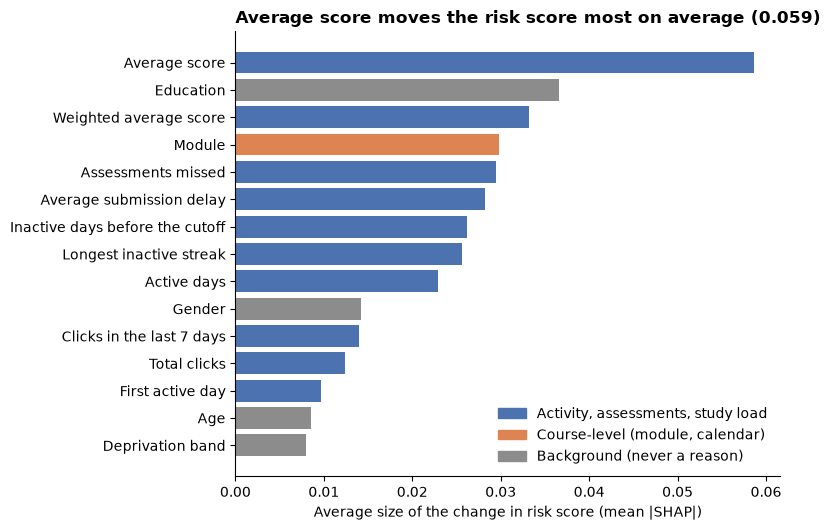

In [4]:
colour = {"behaviour": plots.ON_TRACK, "study": plots.ON_TRACK, "course": COURSE_COLOUR, "background": plots.NEUTRAL}
mean_abs = contrib.abs().mean().sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh([short_label(f) for f in mean_abs.index], mean_abs.values, color=[colour[group_of(f)] for f in mean_abs.index])
ax.set_xlabel("Average size of the change in risk score (mean |SHAP|)")
ax.legend(handles=[Patch(color=plots.ON_TRACK, label="Activity, assessments, study load"),
                   Patch(color=COURSE_COLOUR, label="Course-level (module, calendar)"),
                   Patch(color=plots.NEUTRAL, label="Background (never a reason)")], loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
top = mean_abs.index[-1]
ax.set_title(f"{short_label(top)} moves the risk score most on average ({mean_abs.iloc[-1]:.3f})",
             loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()

The share of all score movement that comes from each group of inputs.

In [5]:
total = contrib.abs().sum(axis=0)
share = total.groupby(group_of).sum() / total.sum()
names = {"behaviour": "Activity and assessments", "study": "Study load and previous attempts",
         "course": "Course-level (module, calendar)", "background": "Background factors"}
share.rename(names).sort_values(ascending=False).map("{:.1%}".format).to_frame("Share of score movement")

,Share of score movement
Activity and assessments,70.1%
Background factors,17.9%
"Course-level (module, calendar)",8.8%
Study load and previous attempts,3.1%


Which input the sentence names first, across the flagged students in the sample.

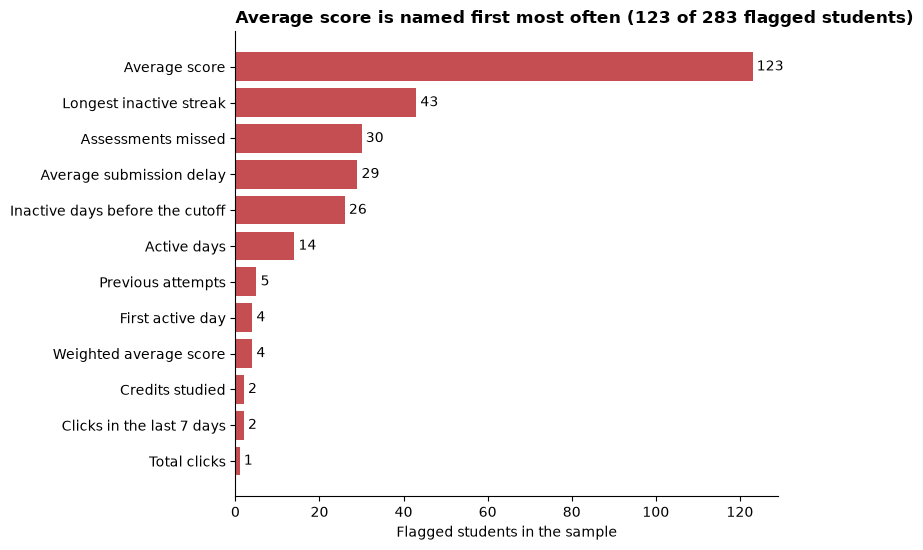

In [6]:
flagged = sample.loc[scores >= threshold, features]
first = pd.Series([
    (lambda r: short_label(r.index[0]) if len(r) else "None")(
        explain_student(model, flagged.iloc[[i]], threshold, explainer).reasons(1))
    for i in range(len(flagged))
]).value_counts()
first = first[::-1]
fig, ax = plt.subplots(figsize=(8, 0.35 * len(first) + 1.4))
bars = ax.barh(first.index, first.values, color=plots.AT_RISK)
ax.bar_label(bars, padding=3)
ax.set_xlabel("Flagged students in the sample")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{first.index[-1]} is named first most often ({first.iloc[-1]} of {len(flagged)} flagged students)",
             loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()

A synthetic student built from the median values of at-risk students in the training presentations (not a real student).

In [7]:
at_risk_train = train.loc[train["at_risk"] == 1, features]
profile = {c: at_risk_train[c].median() if at_risk_train[c].dtype.kind in "if" else at_risk_train[c].mode()[0]
           for c in features}
synthetic = pd.DataFrame([profile])
synthetic.T.rename(columns={0: "Synthetic value"})

,Synthetic value
code_module,FFF
total_clicks,151.0
active_days,10.0
avg_clicks_per_active_day,15.310096
clicks_last_7d,12.0
clicks_prev_7d,24.0
click_trend,-2.0
first_active_day,-8.0
n_submitted,1.0
mean_score,70.0


The explanation chart for the synthetic student.

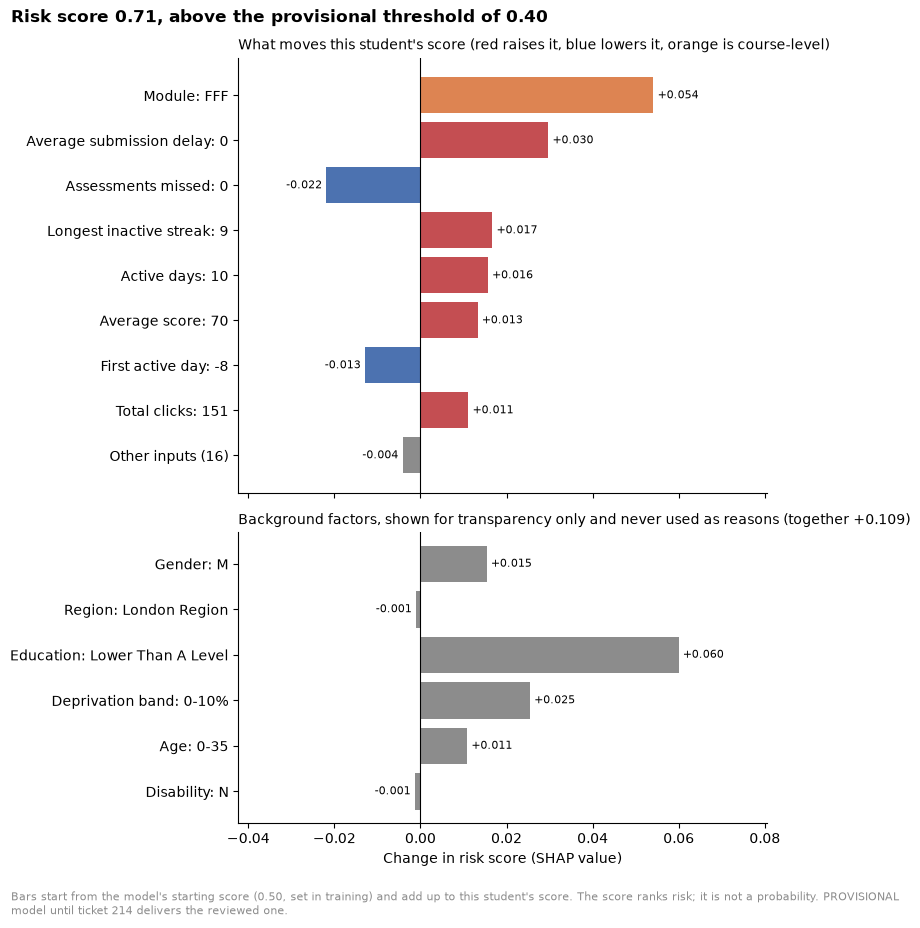

In [8]:
example = explain_student(model, synthetic, threshold, explainer)
fig = plot_explanation(example)

The plain-language sentence for the synthetic student.

In [9]:
print(textwrap.fill(example.sentence, 100))

Risk score 0.71 (provisional threshold 0.40): At Risk. Raising it most: submitting on the due date
on average, a longest run of 9 days without activity and 10 active days by Day 30. Lowering it most:
no assessments missed and first active 8 days before the module started. Course-level patterns, not
about the student: being on module FFF also raises it. Background factors are shown separately and
are not used as reasons.


3D view: the average provisional risk score of validation students, by active-days band and average-score band (bands with fewer than 20 students are left empty).

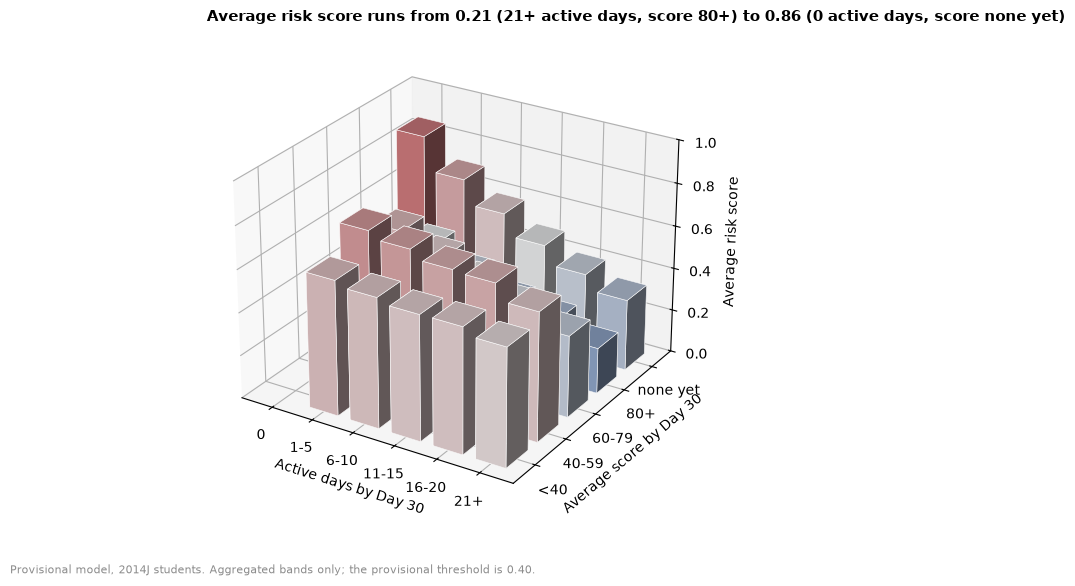

In [10]:
val_scores = pd.Series(model.predict_proba(val[features])[:, 1], index=val.index)
day_bands = pd.cut(val["active_days"], [-1, 0, 5, 10, 15, 20, 60], labels=["0", "1-5", "6-10", "11-15", "16-20", "21+"])
score_bands = pd.cut(val["mean_score"], [-1, 40, 60, 80, 101], labels=["<40", "40-59", "60-79", "80+"])
score_bands = score_bands.cat.add_categories("none yet").fillna("none yet")
cells = val_scores.groupby([day_bands, score_bands], observed=False).agg(["mean", "size"])
mean = cells["mean"].where(cells["size"] >= 20).unstack()
cmap = LinearSegmentedColormap.from_list("risk", [plots.ON_TRACK, "#F2F2F2", plots.AT_RISK])
fig = plt.figure(figsize=(9, 6.4))
ax = fig.add_subplot(projection="3d")
for i, day in enumerate(mean.index):
    for j, band in enumerate(mean.columns):
        z = mean.loc[day, band]
        if pd.notna(z):
            ax.bar3d(i, j, 0, 0.7, 0.7, z, color=cmap(z), edgecolor="white", linewidth=0.4, shade=True)
ax.set_xticks(np.arange(len(mean.index)) + 0.35, mean.index)
ax.set_yticks(np.arange(len(mean.columns)) + 0.35, mean.columns)
ax.set_xlabel("Active days by Day 30")
ax.set_ylabel("Average score by Day 30")
ax.set_zlabel("Average risk score")
ax.set_zlim(0, 1)
ax.view_init(elev=26, azim=-58)
hi, lo = mean.stack().idxmax(), mean.stack().idxmin()
ax.set_title(f"Average risk score runs from {mean.stack().min():.2f} ({lo[0]} active days, score {lo[1]}) "
             f"to {mean.stack().max():.2f} ({hi[0]} active days, score {hi[1]})", loc="left", fontsize=11, fontweight="bold")
fig.text(0.02, 0.03, f"Provisional model, {TEST_PRESENTATION} students. Aggregated bands only; "
         f"the provisional threshold is {threshold:.2f}.", fontsize=8, color=plots.NEUTRAL)
plt.show()

## Limits

- The model is PROVISIONAL. It stands in for the reviewed model from ticket 214 and should be replaced when that lands.
- Background factors are kept out of every sentence and chart reason, but the model still uses them, so they still shift the score (see the share table). Whether to keep them as model inputs is a decision for ticket 214.
- The score ranks risk. It is not a probability: the forest uses balanced class weights, so the starting score is 0.50 rather than the at-risk rate.
- SHAP splits credit between related inputs (for example average score and weighted score), so a single input can look smaller than the idea it shares. The sentence names one input per idea.
- Contributions describe how the model reaches its score. They do not say what caused a student's outcome, or what would change it.
- The threshold comes from training presentations only. 2013B is scored by a model trained on the later training presentations, so that fold is not strictly time-ordered.